# 01 · Data: exploration and preprocessing
**DNN Project 2 – Group 1** · Alphabet (GOOGL) daily stock data

This notebook covers everything that happens to the data before modelling, in the order the requirements ask for:

| Section | Requirement | What it does |
|---|---|---|
| 1 | – | Imports, paths and the settings used everywhere below |
| 2–4 | §4.1–4.3 | Load the raw CSV, put it in time order, check for missing or impossible values |
| 5 | §4.4 | Look at the columns and decide which ones feed the model |
| 6 | §4.5 | Min-Max scaling, fitted on the training rows only |
| 7 | §4.6 | Turn the series into (30 days in → next day's close out) sequences |
| 8 | §4.7 | Assertions that no future information reaches the inputs |
| 9 | §5 | Chronological 70 / 15 / 15 split, and what it implies for the models |
| 10 | – | Write the arrays and scalers that notebook 02 reads |

**Reads** `../data/GOOGL.csv`.
**Writes** `../data/processed/` (arrays and scalers for notebook 02) and `../results/01_data/` (figures).

The models, metrics and experiments are in `02_model_training.ipynb`.

## 1. Setup

Everything configurable lives in the next cell, so no constant is buried further down. `WINDOW`, `TRAIN_RATIO`
and `FEATURES` are the three settings that change the experiment.

In [1]:
import os

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

CSV_PATH = "../data/GOOGL.csv"        # keep GOOGL.csv in data/, next to the README
OUT_DIR = "../data/processed"         # arrays + scalers for notebook 02
RESULTS_DIR = "../results/01_data"    # figures from this notebook
os.makedirs(OUT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

WINDOW = 30                           # requirement §4.6: 30 trading days in, next day's close out
STUDY_WINDOWS = [10, 20, 60]          # extra window lengths for the sequence-length study (notebook 02, section 9)
TRAIN_RATIO, VAL_RATIO = 0.70, 0.15   # requirement §5, test = remaining 15%
FEATURES = ["Close"]                  # requirement §4.4: Close is the minimum input
# FEATURES = ["Open", "High", "Low", "Close", "Volume"]   # optional multivariate run
TARGET = "Close"


def save(name):
    """Save the current figure into RESULTS_DIR and show it."""
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, name), dpi=150)
    plt.show()

## 2. Load and inspect

### 2.1 Read the CSV
Shape, column types and the first rows, to confirm the file is the one we expect.

In [2]:
df = pd.read_csv(CSV_PATH)
print("Shape:", df.shape)
print("\nData types:")
print(df.dtypes)
df.head()

Shape: (4431, 7)

Data types:
Date          object
Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume         int64
dtype: object


,Date,Open,High,Low,Close,Adj Close,Volume
0,2004-08-19,50.050049,52.082081,48.028027,50.220219,50.220219,44659096
1,2004-08-20,50.555557,54.594597,50.300301,54.209209,54.209209,22834343
2,2004-08-23,55.430431,56.796799,54.579578,54.754753,54.754753,18256126
3,2004-08-24,55.675674,55.855858,51.836838,52.487488,52.487488,15247337
4,2004-08-25,52.532532,54.054054,51.991993,53.053055,53.053055,9188602


### 2.2 Summary statistics
Ranges and spread of every numeric column. The point to notice is how wide the `Close` range is:
the price grows by a factor of about 60 across the file, which is what makes the split in section 9 difficult.

In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Open,4431.0,6.930873e+02,6.451188e+02,49.644646,2.485586e+02,4.349249e+02,1.007365e+03,3.025000e+03
High,4431.0,6.997356e+02,6.513312e+02,50.920921,2.508534e+02,4.378879e+02,1.020650e+03,3.030930e+03
Low,4431.0,6.860788e+02,6.385795e+02,48.028027,2.458133e+02,4.326877e+02,9.972750e+02,2.977980e+03
Close,4431.0,6.930974e+02,6.451878e+02,50.055054,2.484159e+02,4.353303e+02,1.007790e+03,2.996770e+03
Adj Close,4431.0,6.930974e+02,6.451878e+02,50.055054,2.484159e+02,4.353303e+02,1.007790e+03,2.996770e+03
Volume,4431.0,6.444992e+06,7.690351e+06,465600.000000,1.695600e+06,3.778418e+06,8.002390e+06,8.215117e+07


## 3. Sort chronologically

A time series model is only valid if the rows are in time order, so `Date` becomes a real datetime and the frame is
sorted by it. The prints confirm the order is strictly increasing and that no trading day appears twice.
`n` is the number of rows and is reused by every section below.

In [4]:
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)
n = len(df)

print("Rows:", n)
print("Date range:", df["Date"].min().date(), "->", df["Date"].max().date())
print("Chronological:", df["Date"].is_monotonic_increasing)
print("Duplicate dates:", df["Date"].duplicated().sum())

Rows: 4431
Date range: 2004-08-19 -> 2022-03-24
Chronological: True
Duplicate dates: 0


## 4. Missing and invalid values

Rather than imputing blindly, the cell below first checks whether there is anything to fix: empty cells,
non-positive prices, rows where `High < Low`, unusually long gaps between trading days, and whether
`Adj Close` differs from `Close`.

In [5]:
print("Missing values per column:")
print(df.isna().sum())
print("\nNon-positive prices:", (df[["Open", "High", "Low", "Close"]] <= 0).sum().sum())
print("High < Low rows:", (df["High"] < df["Low"]).sum())
print("Largest gap between trading days:", int(df["Date"].diff().dt.days.max()), "days")
print("Close == Adj Close everywhere:", np.allclose(df["Close"], df["Adj Close"]))

Missing values per column:
Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64

Non-positive prices: 0
High < Low rows: 0
Largest gap between trading days: 5 days
Close == Adj Close everywhere: True


**Result: the file is clean.** No missing or impossible values, so nothing is dropped and nothing is imputed —
adding a `ffill()` / `dropna()` step here would be dead code. If gaps ever did appear, forward-filling prices
would be the right treatment, because it only copies past values and therefore cannot leak future information.
The largest gap (5 days) is a long weekend, not missing data.

## 5. Feature selection

Three figures to decide which columns are worth feeding the model: the level of price and volume over time,
their distributions, and how strongly the columns move together.

### 5.1 Price and volume over time

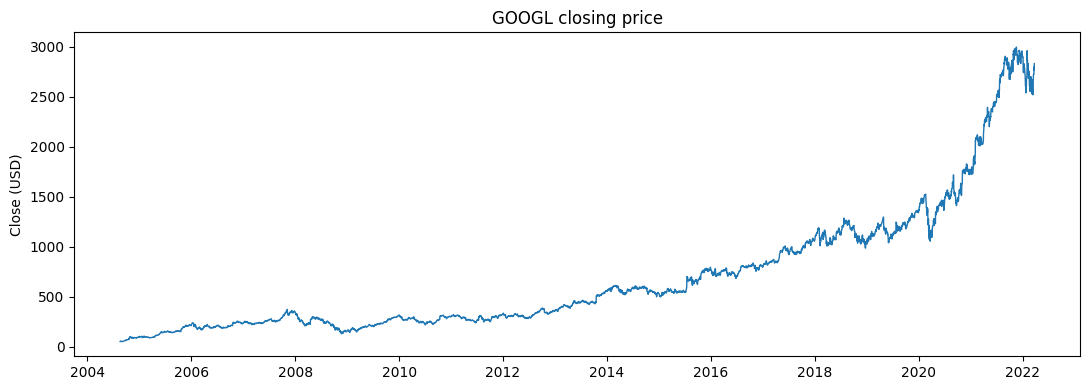

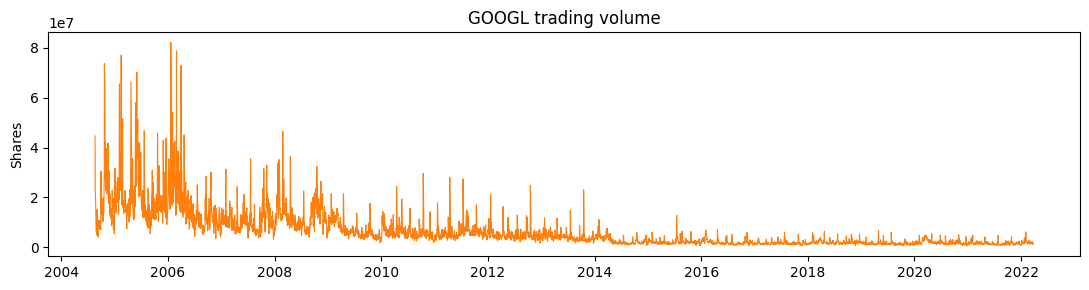

In [6]:
plt.figure(figsize=(11, 4))
plt.plot(df["Date"], df["Close"], linewidth=1)
plt.title("GOOGL closing price")
plt.ylabel("Close (USD)")
save("eda_close_price.png")

plt.figure(figsize=(11, 3))
plt.plot(df["Date"], df["Volume"], linewidth=0.8, color="tab:orange")
plt.title("GOOGL trading volume")
plt.ylabel("Shares")
save("eda_volume.png")

### 5.2 Distributions
The raw `Close` next to the daily log-return `ln(C_t / C_{t-1})`. The two behave very differently, which is the
single most important observation in this notebook.

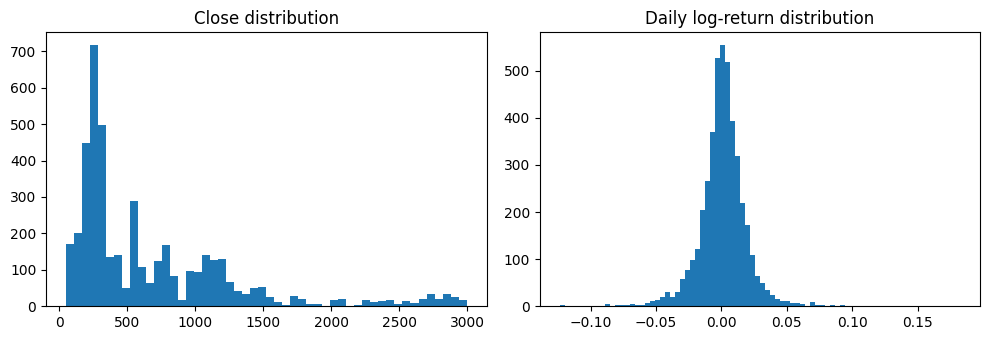

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(df["Close"], bins=50)
axes[0].set_title("Close distribution")
axes[1].hist(np.log(df["Close"]).diff().dropna(), bins=80)
axes[1].set_title("Daily log-return distribution")
save("eda_distributions.png")

### 5.3 Correlation between columns

Correlation with Close:
Open      0.9998
High      0.9999
Low       0.9999
Close     1.0000
Volume   -0.4543
Name: Close, dtype: float64


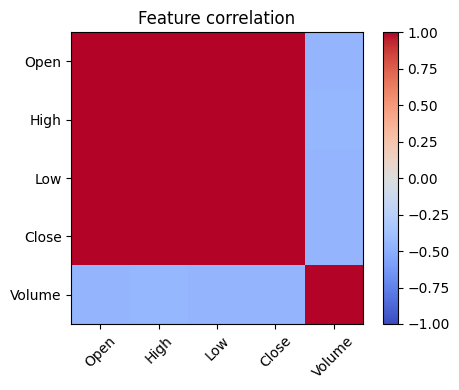

In [8]:
corr = df[["Open", "High", "Low", "Close", "Volume"]].corr()
print("Correlation with Close:")
print(corr["Close"].round(4))

plt.figure(figsize=(5, 4))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(corr)), corr.columns, rotation=45)
plt.yticks(range(len(corr)), corr.columns)
plt.colorbar()
plt.title("Feature correlation")
save("eda_correlation.png")

### 5.4 Decision

**We use `Close` alone** and predict the next day's `Close`:

- Open, High and Low are almost perfectly correlated with Close (r > 0.999), so they carry little new information
  while adding parameters to the input layer.
- Volume is only moderately correlated (r ≈ −0.45) and lives on a completely different scale; it says more about
  volatility than about the next price level.
- `Adj Close` equals `Close` on every row — the file is already adjusted for the 2014 stock split and no dividends
  were paid in this period — so the column is dropped.

The multivariate run stays one commented line away in section 1, in case we want to report it as a side experiment.

The distributions in 5.2 also show why the problem is hard: the price **level** is strongly skewed and climbs from
about 50 to 3,000 USD, while the daily **log-returns** stay centred near zero with a similar spread throughout.
Section 9 returns to this.

In [9]:
print("Input features:", FEATURES, "| target:", TARGET)
df[["Date"] + FEATURES].head()

Input features: ['Close'] | target: Close


,Date,Close
0,2004-08-19,50.220219
1,2004-08-20,54.209209
2,2004-08-23,54.754753
3,2004-08-24,52.487488
4,2004-08-25,53.053055


## 6. Normalization

Min-Max scaling, **fitted on the training rows only**. The training boundary is the 70% mark of the chronological
split; the split itself is applied in section 9, but the scaler needs its boundary now, because
fitting on all rows would leak information from the future into training.

Two scalers are kept: `feature_scaler` for the inputs and `target_scaler` for `Close` alone, which notebook 02
uses to turn predictions back into USD.

In [10]:
train_end = int(n * TRAIN_RATIO)
train_rows = df.iloc[:train_end]

feature_scaler = MinMaxScaler().fit(train_rows[FEATURES])
target_scaler = MinMaxScaler().fit(train_rows[[TARGET]])
series = feature_scaler.transform(df[FEATURES])            # (n, n_features)
target = target_scaler.transform(df[[TARGET]]).ravel()     # (n,)

print(f"training rows  scaled Close: {target[:train_end].min():.3f} -> {target[:train_end].max():.3f}")
print(f"later rows     scaled Close: {target[train_end:].min():.3f} -> {target[train_end:].max():.3f}")
# Later rows go above 1 because the price kept rising after the training period.
# Refitting or clipping would use future information, so we keep it and analyse it in notebook 02, section 10.

training rows  scaled Close: 0.000 -> 1.000
later rows     scaled Close: 0.945 -> 3.751


## 7. Sequence generation

The sequence for day `t` holds days `t-30 … t-1` as input and the `Close` of day `t` as its target, so the label is
always the **next** trading day. `make_sequences` is written as a function because section 10 reuses it for the
other window lengths.

In [11]:
def make_sequences(window):
    """For every day t with a full window: X = series[t-window:t], y = target[t]. Also returns t."""
    t = np.arange(window, n)
    X = np.stack([series[i - window:i] for i in t])
    return X, target[t], t


X, y, t = make_sequences(WINDOW)
print(f"X={X.shape}  y={y.shape}")

X=(4401, 30, 1)  y=(4401,)


## 8. Leakage and sanity checks

Each assertion states one property that must hold. If any of them fails the notebook stops here, which is the
point: a silent off-by-one in the windowing would look like a working model.

In [12]:
assert X.shape == (n - WINDOW, WINDOW, len(FEATURES)) and len(X) == len(y) == len(t)   # dimensions
assert np.all(np.diff(t) == 1)                     # temporal order kept, no gaps
assert np.allclose(X[1][:-1], X[0][1:])            # window slides by exactly one day
assert np.allclose(X[:, -1], series[t - 1])        # newest input day is the day before the target
assert np.allclose(y, target[t])                   # target is the close of that next day
assert np.isclose(target_scaler.data_max_[0], train_rows[TARGET].max())   # scaler saw training rows only
print("all checks passed")

all checks passed


## 9. Chronological split

Earliest 70% train, next 15% validation, most recent 15% test. No shuffling: the test set must stay in the future
relative to training.

Each sequence goes to the split that contains its **target day**, so no target crosses a boundary. The first
validation and test windows therefore take some input days from the end of the previous split — those are past
observations, so nothing leaks, and validation and test keep all 665 target days instead of losing the first 30.

### 9.1 Boundaries and summary
One row per split, with both the USD view (mean, max, how many days exceed the highest training close) and the
scaled view produced in section 6.

In [13]:
val_end = int(n * (TRAIN_RATIO + VAL_RATIO))
bounds = {"train": (0, train_end), "val": (train_end, val_end), "test": (val_end, n)}
train_max = df[TARGET][:train_end].max()


def split(X, y, t):
    return {k: (X[(t >= a) & (t < b)], y[(t >= a) & (t < b)], t[(t >= a) & (t < b)]) for k, (a, b) in bounds.items()}


seq = split(X, y, t)
pd.DataFrame([{
    "split": k,
    "rows": b - a,
    "sequences": len(seq[k][1]),
    "start": df["Date"][a].date(),
    "end": df["Date"][b - 1].date(),
    "Close mean": round(df[TARGET][a:b].mean(), 2),
    "Close max": round(df[TARGET][a:b].max(), 2),
    "days above train max": int((df[TARGET][a:b] > train_max).sum()),
    "scaled Close max": round(target[a:b].max(), 3),
} for k, (a, b) in bounds.items()])

,split,rows,sequences,start,end,Close mean,Close max,days above train max,scaled Close max
0,train,3101,3071,2004-08-19,2016-12-09,350.70,835.74,0,1.000
1,val,665,665,2016-12-12,2019-08-05,1052.03,1296.20,627,1.586
2,test,665,665,2019-08-06,2022-03-24,1930.84,2996.77,665,3.751


### 9.2 Split checks
Target days are strictly ordered across the three splits, and inverse-transforming the test labels returns the
original USD prices.

In [14]:
assert seq["train"][2].max() < seq["val"][2].min()   # target days strictly ordered across splits
assert seq["val"][2].max() < seq["test"][2].min()
back = target_scaler.inverse_transform(seq["test"][1].reshape(-1, 1)).ravel()
assert np.allclose(back, df[TARGET].values[val_end:])   # round trip back to USD
print("split checks passed")

split checks passed


### 9.3 Where the split falls on the price history
The dashed line is the highest close seen during training.

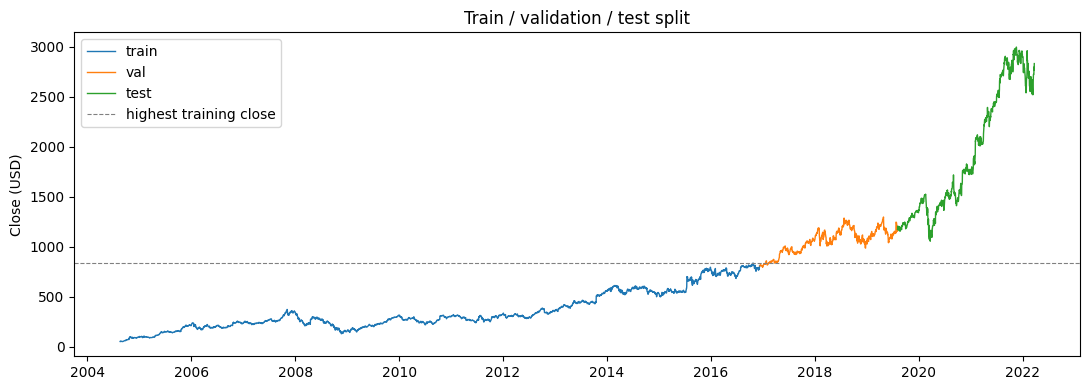

In [15]:
plt.figure(figsize=(11, 4))
for k, (a, b) in bounds.items():
    plt.plot(df["Date"][a:b], df[TARGET][a:b], label=k, linewidth=1)
plt.axhline(train_max, color="grey", linestyle="--", linewidth=0.8, label="highest training close")
plt.title("Train / validation / test split")
plt.ylabel("Close (USD)")
plt.legend()
save("eda_split.png")

### 9.4 What the model actually receives
Left: the same series after scaling, with 1.0 marked — everything above that line is outside the range the scaler
was fitted on. Right: one training sequence, 30 input days and the target day at position 0.

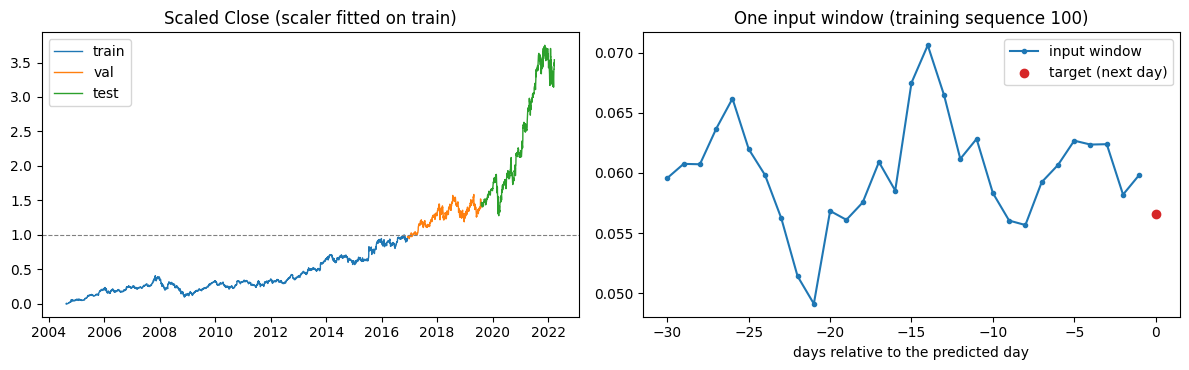

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for k, (a, b) in bounds.items():
    ax[0].plot(df["Date"][a:b], target[a:b], label=k, linewidth=1)
ax[0].axhline(1, color="grey", linestyle="--", linewidth=0.8)
ax[0].set_title("Scaled Close (scaler fitted on train)")
ax[0].legend()

i = 100
ax[1].plot(np.arange(-WINDOW, 0), seq["train"][0][i][:, FEATURES.index(TARGET)], marker="o", markersize=3,
           label="input window")
ax[1].scatter([0], [seq["train"][1][i]], color="tab:red", zorder=3, label="target (next day)")
ax[1].set_title(f"One input window (training sequence {i})")
ax[1].set_xlabel("days relative to the predicted day")
ax[1].legend()
save("preprocessing_check.png")

**Key observation.** The highest training close is about 836 USD, but 627 of the 665 validation days and all 665
test days lie above it. Because the scaler is fitted on training data only, most
validation values and every test value map above 1, and the models are asked to predict price levels they never
saw. Combined with `tanh`, which bounds the recurrent state to [−1, 1], this puts a ceiling on what the networks
can output. It is a consequence of the task definition — absolute price as the target — not a bug in the pipeline,
and it is measured in section 10 of notebook 02.

## 10. Save for notebook 02

One `.npz` per window length: 30 days for the models in notebook 02, plus 10 / 20 / 60 days for the
sequence-length study in section 9 of notebook 02. All of them use the same split and the same train-fitted
scalers, so only the window length differs. The two scalers are saved separately so notebook 02 can invert
predictions without re-reading the CSV.

In [17]:
for w in [WINDOW] + STUDY_WINDOWS:
    s = seq if w == WINDOW else split(*make_sequences(w))
    np.savez(
        os.path.join(OUT_DIR, f"sequences_w{w}.npz"),
        **{f"X_{k}": Xs for k, (Xs, _, _) in s.items()},
        **{f"y_{k}": ys for k, (_, ys, _) in s.items()},
        dates_test=df["Date"].values[s["test"][2]].astype("datetime64[D]").astype(str),
        features=np.array(FEATURES),
    )
joblib.dump(feature_scaler, os.path.join(OUT_DIR, "feature_scaler.joblib"))
joblib.dump(target_scaler, os.path.join(OUT_DIR, "target_scaler.joblib"))
print(sorted(os.listdir(OUT_DIR)))

['feature_scaler.joblib', 'sequences_w10.npz', 'sequences_w20.npz', 'sequences_w30.npz', 'sequences_w60.npz', 'target_scaler.joblib']
